# Model BISINDO dengan ResNet50

In [1]:
import os
import json
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

print("TensorFlow Version:", tf.__version__)


TensorFlow Version: 2.15.0


# KONFIGURASI DATASET

In [2]:
DATASET_DIR = Path("Data")   # folder dataset utama
IMG_SIZE = 224                  # ukuran input standar ResNet50
BATCH_SIZE = 32
SEED = 42
EPOCHS = 25

VALID_EXT = (".png", ".jpg", ".jpeg", ".bmp", ".webp")

In [3]:
image_paths = []
labels = []

class_folders = sorted([p for p in DATASET_DIR.iterdir() if p.is_dir()])

if len(class_folders) == 0:
    raise ValueError("Tidak ada subfolder kelas di dalam folder dataset.")

for class_folder in class_folders:
    class_name = class_folder.name
    for file_path in class_folder.rglob("*"):
        if file_path.is_file() and file_path.suffix.lower() in VALID_EXT:
            image_paths.append(str(file_path))
            labels.append(class_name)

image_paths = np.array(image_paths)
labels = np.array(labels)
class_names = sorted(np.unique(labels))
class_to_index = {name: idx for idx, name in enumerate(class_names)}
y = np.array([class_to_index[label] for label in labels])

print("Total gambar  :", len(image_paths))
print("Jumlah kelas  :", len(class_names))
print("Nama kelas    :", class_names)

if len(image_paths) == 0:
    raise ValueError("Tidak ada file gambar yang ditemukan di dalam folder dataset.")

Total gambar  : 3120
Jumlah kelas  : 26
Nama kelas    : ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']


# DISTRIBUSI DATA PER KELAS

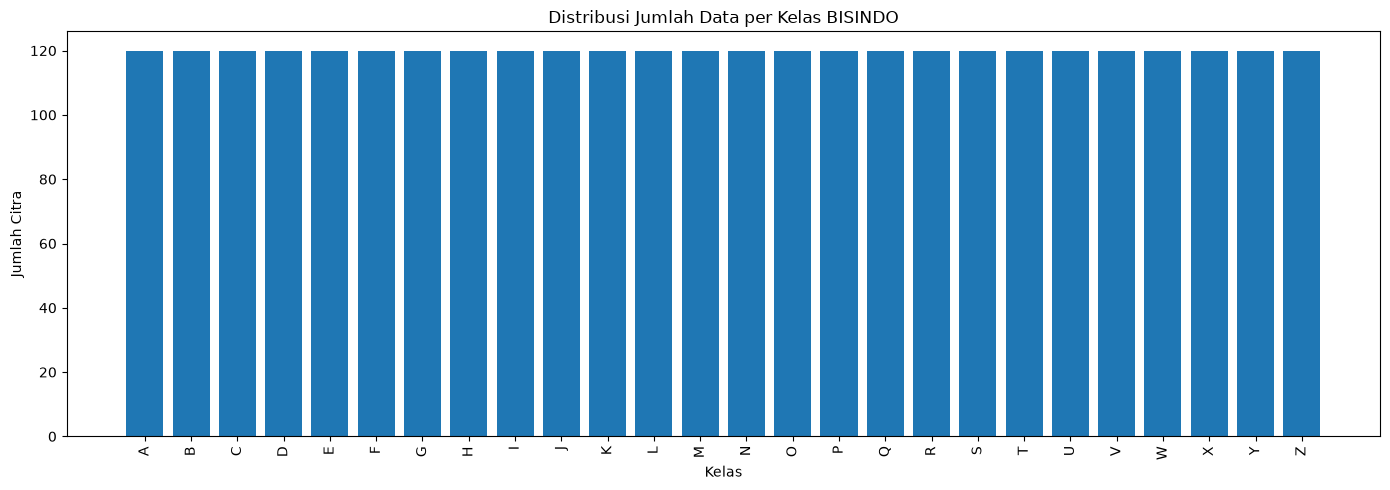

In [4]:
label_counts = Counter(labels)

plt.figure(figsize=(14, 5))
plt.bar(label_counts.keys(), label_counts.values())
plt.title("Distribusi Jumlah Data per Kelas BISINDO")
plt.xlabel("Kelas")
plt.ylabel("Jumlah Citra")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


# SPLIT DATA: TRAIN, VALIDATION, TEST

In [5]:
# 70% train, 15% validation, 15% test

X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Data train     :", len(X_train))
print("Data validation:", len(X_val))
print("Data test      :", len(X_test))

Data train     : 2184
Data validation: 468
Data test      : 468


# PREPROCESSING GAMBAR

In [6]:
def load_and_preprocess_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32)
    img = preprocess_input(img)  # preprocessing khusus ResNet50
    return img, label


def make_dataset(paths, labels, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(paths), seed=SEED)
    ds = ds.map(load_and_preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(X_train, y_train, shuffle=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)


# VISUALISASI CONTOH GAMBAR

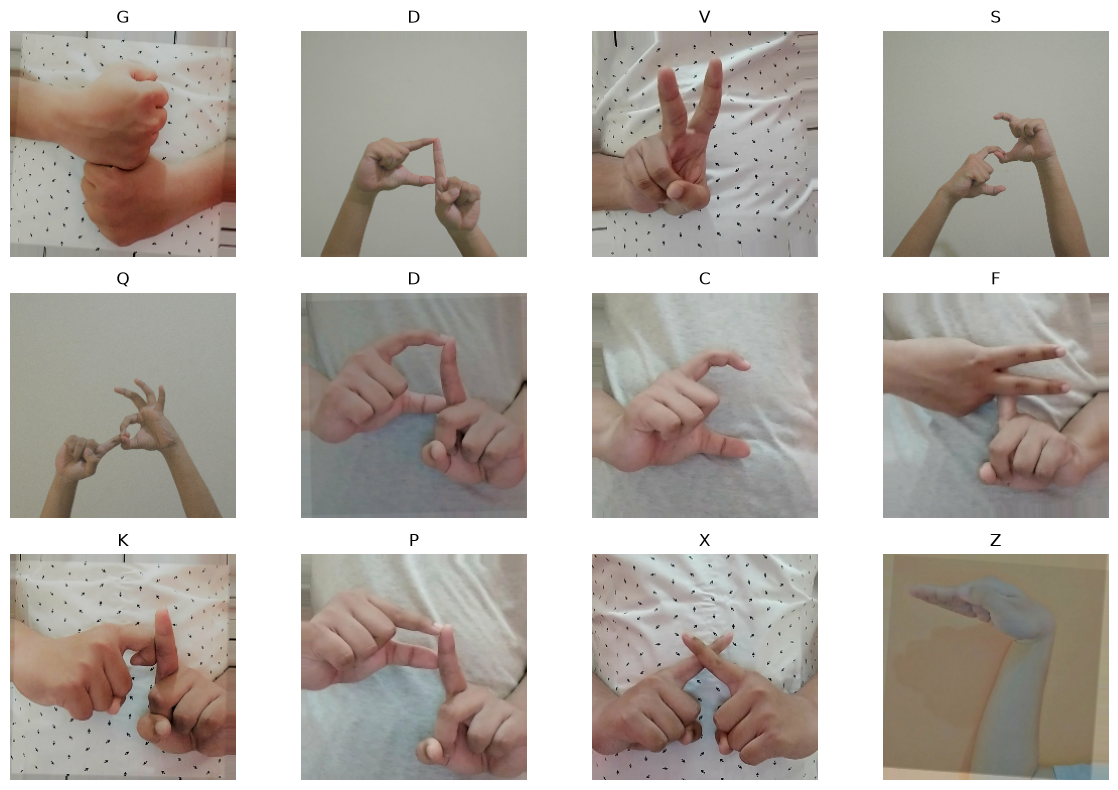

In [7]:
plt.figure(figsize=(12, 8))

sample_indices = random.sample(range(len(X_train)), min(12, len(X_train)))

for i, idx in enumerate(sample_indices):
    img_raw = tf.io.read_file(X_train[idx])
    img_raw = tf.image.decode_image(img_raw, channels=3, expand_animations=False)
    img_raw = tf.image.resize(img_raw, [IMG_SIZE, IMG_SIZE])
    img_raw = img_raw.numpy().astype("uint8")

    plt.subplot(3, 4, i + 1)
    plt.imshow(img_raw)
    plt.title(class_names[y_train[idx]])
    plt.axis("off")

plt.tight_layout()
plt.show()

# AUGMENTASI DATA

In [8]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomTranslation(0.08, 0.08),
], name="data_augmentation")

# MEMBANGUN MODEL RESNET50

In [9]:
num_classes = len(class_names)

base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Tahap awal: layer ResNet50 dibekukan agar training lebih stabil
base_model.trainable = False

inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.4)(x)
outputs = Dense(num_classes, activation="softmax")(x)

model = Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 data_augmentation (Sequent  (None, 224, 224, 3)       0         
 ial)                                                            
                                                                 
 resnet50 (Functional)       (None, 7, 7, 2048)        23587712  
                                                                 
 global_average_pooling2d (  (None, 2048)              0         
 GlobalAveragePooling2D)                                         
                                                                 
 dense (Dense)               (None, 256)               524544    
                                                                 
 dropout (Dropout)           (None, 256)               0    

# CALLBACK TRAINING

In [10]:
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
]

# TRAINING MODEL

In [11]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/25


69/69 [==============================] - 149s 2s/step - loss: 2.5436 - accuracy: 0.2761 - val_loss: 1.2326 - val_accuracy: 0.7009
Epoch 2/25
69/69 [==============================] - 146s 2s/step - loss: 1.2286 - accuracy: 0.6493 - val_loss: 0.5838 - val_accuracy: 0.8526
Epoch 3/25
69/69 [==============================] - 152s 2s/step - loss: 0.7082 - accuracy: 0.7912 - val_loss: 0.3742 - val_accuracy: 0.9038
Epoch 4/25
69/69 [==============================] - 147s 2s/step - loss: 0.5024 - accuracy: 0.8590 - val_loss: 0.2692 - val_accuracy: 0.9402
Epoch 5/25
69/69 [==============================] - 146s 2s/step - loss: 0.3627 - accuracy: 0.8942 - val_loss: 0.1998 - val_accuracy: 0.9594
Epoch 6/25
69/69 [==============================] - 147s 2s/step - loss: 0.3085 - accuracy: 0.9093 - val_loss: 0.1288 - val_accuracy: 0.9915
Epoch 7/25
69/69 [==============================] - 145s 2s/step - loss: 0.2412 - accuracy: 0.9332 - val_loss: 0.1331 - val_accuracy: 0.9744
Epoch 8/25


# EVALUASI MODEL PADA DATA TEST

In [13]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)

print("Test Loss     :", test_loss)
print("Test Accuracy :", test_acc)

Test Loss     : 0.033748749643564224
Test Accuracy : 0.9935897588729858


# EVALUASI GRAPH

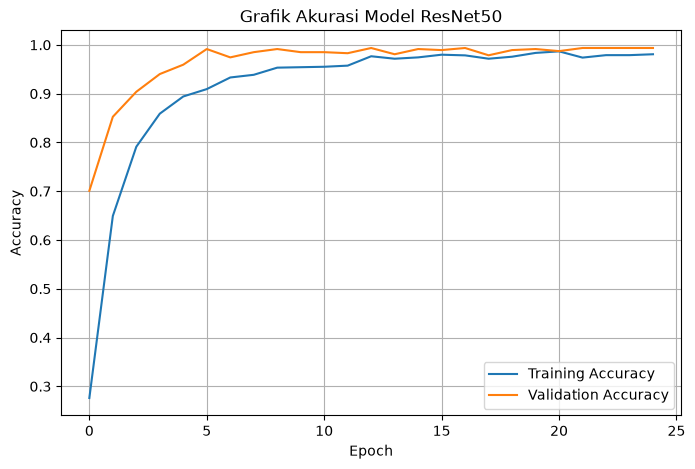

In [15]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Grafik Akurasi Model ResNet50")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

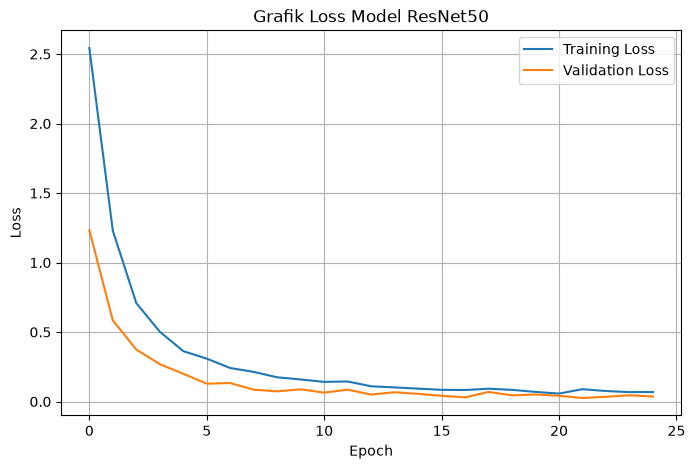

In [16]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Grafik Loss Model ResNet50")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

# REPORT

In [17]:
y_true = []
y_pred = []

for images, labels_batch in test_ds:
    predictions = model.predict(images, verbose=0)
    y_true.extend(labels_batch.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

print(classification_report(y_true, y_pred, target_names=class_names))

              precision    recall  f1-score   support

           A       1.00      1.00      1.00        18
           B       1.00      0.89      0.94        18
           C       1.00      1.00      1.00        18
           D       0.95      1.00      0.97        18
           E       1.00      1.00      1.00        18
           F       0.95      1.00      0.97        18
           G       1.00      1.00      1.00        18
           H       1.00      1.00      1.00        18
           I       1.00      1.00      1.00        18
           J       1.00      1.00      1.00        18
           K       1.00      1.00      1.00        18
           L       1.00      1.00      1.00        18
           M       1.00      1.00      1.00        18
           N       1.00      1.00      1.00        18
           O       1.00      1.00      1.00        18
           P       0.95      1.00      0.97        18
           Q       1.00      1.00      1.00        18
           R       1.00    

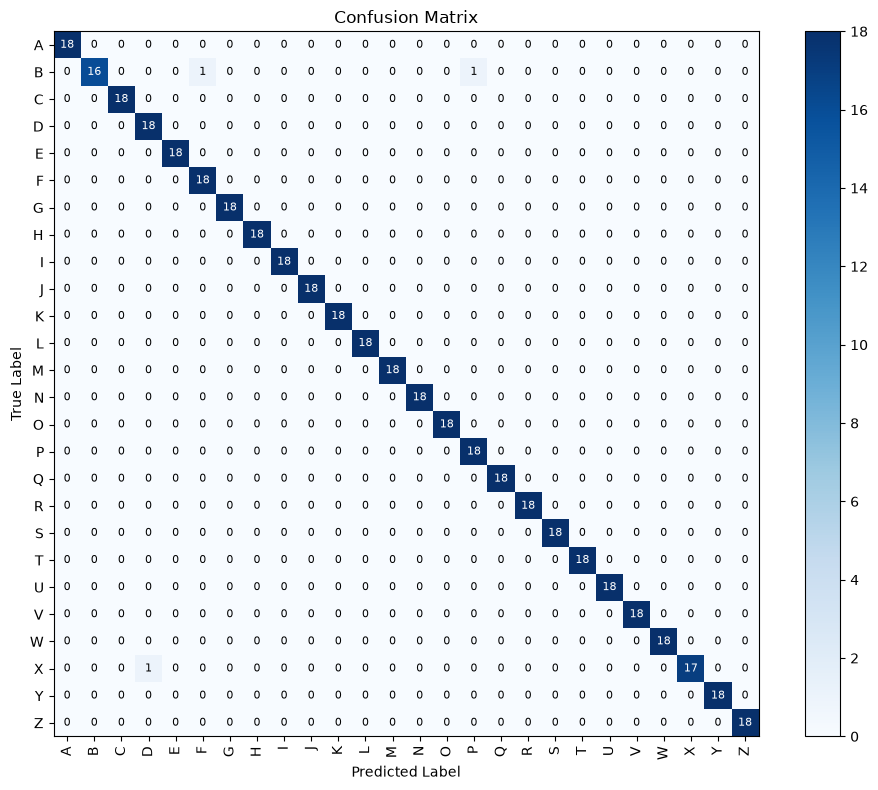

In [20]:

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
plt.imshow(cm, cmap="Blues")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j, i, cm[i, j],
            ha="center", va="center",
            color="white" if cm[i, j] > cm.max()/2 else "black",
            fontsize=8
        )
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(range(num_classes), class_names, rotation=90)
plt.yticks(range(num_classes), class_names)
plt.colorbar()
plt.tight_layout()
plt.show()


# SIMPAN MODEL DAN NAMA KELAS

In [21]:
model.save("resnet50_bisindo.h5")

# Simpan nama kelas BISINDO A-Z dalam format .npy
np.save("class_names_bisindo.npy", np.array(class_names))

print("Model berhasil disimpan sebagai: resnet50_bisindo.h5")
print("Nama kelas berhasil disimpan sebagai: class_names_bisindo.npy")


c:\Users\ACER\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


Model berhasil disimpan sebagai: resnet50_bisindo.h5
Nama kelas berhasil disimpan sebagai: class_names_bisindo.npy
